# 06 — Diagnóstico dos erros no teste (seção 23 do v5)

**Lê:** `previsoes_teste` (05), `selecao_modelo.json`, `perfis_treino`, `panel_base` até `TRAIN_TARGET_END`, teste (trava, finalidade *diagnostico*).  
**Grava:** tabelas e figuras `diagnostico_*`.

**Correção em relação ao v5:** o modelo do diagnóstico principal é o escolhido em `selecao_modelo.json` (parâmetro `DIAG_MODELO_PRINCIPAL` do config). No v5 ele estava fixo em `CatBoost_MAE`, embora a seleção tenha escolhido `LightGBM_MAE_Exog`.

In [1]:
# === SETUP (idêntico em todos os notebooks; só muda NOTEBOOK) ===
NOTEBOOK = "06_diagnostico"
RAIZ = "/content/drive/MyDrive/tcc_fluxo"      # Colab. Localmente: caminho da pasta do projeto (ou deixe None)

import os, sys
try:
    from google.colab import drive
    drive.mount("/content/drive")
    !pip install -q -r {RAIZ}/requirements.txt
except ImportError:                              # fora do Colab
    RAIZ = os.environ.get("TCC_RAIZ") or None
    if RAIZ is None:
        from pathlib import Path
        RAIZ = str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").is_file()))
sys.path.insert(0, f"{RAIZ}/src")
%load_ext autoreload
%autoreload 2

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tcc_fluxo import iniciar
C, A = iniciar(RAIZ, notebook=NOTEBOOK)

AVISO de reprodutibilidade: pandas=3.1.1; referência recomendada=2.2.3
AVISO de reprodutibilidade: numpy=2.5.4; referência recomendada=2.1.3
AVISO de reprodutibilidade: scikit-learn=1.9.1; referência recomendada=1.6.1
Notebook: 06_diagnostico | execução: v6_modular | raiz: C:\Users\andre\OneDrive\Documentos\Projetos\Tccv2\tcc_fluxo_modular_v6


In [2]:
from tcc_fluxo import diagnostico as D, metricas as M, graficos

sel = A.carregar_json("selecao_modelo")
MAIN = sel["modelo_escolhido"] if C.DIAG_MODELO_PRINCIPAL == "escolhido" else C.DIAG_MODELO_PRINCIPAL
comparison = A.carregar_df("previsoes_teste")
test = A.carregar_teste(finalidade="diagnostico")
hist = A.carregar_historico_treino()
profile = A.carregar_df("perfis_treino").set_index("seller_id")
scale_final = M.seller_scales(hist, C.TRAIN_TARGET_END)

MODELS = [m for m in D.ALL_DIAG if f"pred_{m}" in comparison.columns]
FOCUS = [m for m in D.FOCUS if m in MODELS]
assert MAIN in MODELS, f"{MAIN} sem previsões no teste"
thr = D.limiares(hist)
print(f"Modelo do diagnóstico principal: {MAIN}")
print(f"Pico > R$ {thr['PEAK_THRESHOLD']:,.2f} | sinal ≥ R$ {thr['SIGNAL_THRESHOLD']:,.2f} (P90/P10 da receita positiva no treino)")
diag = D.base_diagnostico(comparison, profile, test, MODELS, thr)

Modelo do diagnóstico principal: LightGBM_MAE_Exog
Pico > R$ 982.18 | sinal ≥ R$ 55.09 (P90/P10 da receita positiva no treino)


### 23.1 Diagnóstico resumido de todos os modelos

In [3]:
geral = D.diagnostico_geral(diag, MODELS, thr["SIGNAL_THRESHOLD"])
A.tabela(geral, "diagnostico_geral_modelos.csv")
display(geral.set_index("Modelo").style.format("{:,.2f}"))

,n,MAE,MAE zero,MAE positiva,Viés R$,Viés %,Viés R$ (sem receita),Viés R$ (com receita),P90 erro,P95 erro,P99 erro,Erro máximo,% falso sinal,% venda não sinalizada,% do erro em semanas sem receita,Real médio,Previsto médio
Modelo,,,,,,,,,,,,,,,,,
Naive,"29,580.00",137.69,43.34,334.70,0.80,0.50,43.34,-88.01,385.88,651.43,"1,684.95","8,920.55",14.05,37.39,21.28,159.75,160.55
MediaMovel4,"29,580.00",127.30,50.58,287.50,2.93,1.83,50.58,-96.58,325.22,557.34,"1,477.82","7,824.36",21.96,23.88,26.87,159.75,162.68
HistGB_MAE,"29,580.00",157.39,0.00,486.02,-156.65,-98.06,0.00,-483.74,407.17,785.89,"2,383.83","11,087.61",0.00,99.69,0.00,159.75,3.10
HistGB_Poisson,"29,580.00",134.04,67.78,272.38,14.98,9.38,67.78,-95.27,295.14,505.66,"1,370.91","8,901.19",33.22,11.73,34.19,159.75,174.73
LightGBM_MAE,"29,580.00",110.15,13.11,312.78,-59.76,-37.41,13.11,-211.91,297.19,525.76,"1,462.64","8,725.20",6.78,46.04,8.05,159.75,99.99
LightGBM_MAE_Exog,"29,580.00",110.63,12.17,316.23,-56.80,-35.56,12.17,-200.82,303.40,537.14,"1,493.96","8,611.42",5.23,50.31,7.44,159.75,102.94
CatBoost_MAE,"29,580.00",110.11,12.45,314.03,-58.20,-36.43,12.45,-205.70,295.38,531.43,"1,436.54","9,546.30",5.03,49.83,7.64,159.75,101.55
CatBoost_MAE_Exog,"29,580.00",110.97,10.41,320.94,-76.20,-47.70,10.41,-257.03,294.28,531.83,"1,527.58","9,781.63",4.60,51.84,6.34,159.75,83.55
CatBoost_MAE_raw,"29,580.00",112.96,25.20,296.19,-44.39,-27.79,25.20,-189.72,282.84,511.11,"1,422.20","9,070.00",12.22,36.14,15.09,159.75,115.36


### 23.2 Semanas sem × com receita e faixas de valor

In [4]:
diag["grupo"] = np.where(diag["y"] > 0, "com receita", "sem receita")
zp = D.group_table(diag, "grupo", list(dict.fromkeys([MAIN, "Naive"])))
faixas = D.group_table(diag, "faixa_real", list(dict.fromkeys([m for m in ["LightGBM_MAE", "LightGBM_MAE_Exog", "CatBoost_MAE",
                                                         "CatBoost_MAE_Exog", MAIN, "Naive", "CatBoost_Tweedie"] if m in MODELS])))
A.tabela(zp, "diagnostico_principal_zero_positivo.csv"); A.tabela(faixas, "diagnostico_faixas_valor.csv")
display(zp); display(faixas)
z = diag["y"] == 0
print(f"Em semanas sem receita, {MAIN} prevê exatamente 0 em {diag.loc[z, f'pred_{MAIN}'].eq(0).mean():.1%} "
      f"(Naive: {diag.loc[z, 'pred_Naive'].eq(0).mean():.1%}).")

,grupo,modelo,n_linhas,% linhas,real médio,previsto médio,MAE,viés R$,viés %,% do erro absoluto total
0,com receita,LightGBM_MAE_Exog,9579,32.3834,493.3075,292.4884,316.2350,-200.8192,-40.7087,92.5636
1,com receita,Naive,9579,32.3834,493.3075,405.2964,334.6954,-88.0111,-17.8410,78.7178
2,sem receita,LightGBM_MAE_Exog,20001,67.6166,0.0000,12.1675,12.1675,12.1675,NaN,7.4364
3,sem receita,Naive,20001,67.6166,0.0000,43.3373,43.3373,43.3373,NaN,21.2822


,faixa_real,modelo,n_linhas,% linhas,real médio,previsto médio,MAE,viés R$,viés %,% do erro absoluto total
0,zero,LightGBM_MAE,20001,67.6166,0.0000,13.1073,13.1073,13.1073,NaN,8.0459
1,zero,LightGBM_MAE_Exog,20001,67.6166,0.0000,12.1675,12.1675,12.1675,NaN,7.4364
2,zero,CatBoost_MAE,20001,67.6166,0.0000,12.4466,12.4466,12.4466,NaN,7.6432
3,zero,CatBoost_MAE_Exog,20001,67.6166,0.0000,10.4102,10.4102,10.4102,NaN,6.3432
4,zero,Naive,20001,67.6166,0.0000,43.3373,43.3373,43.3373,NaN,21.2822
5,zero,CatBoost_Tweedie,20001,67.6166,0.0000,59.6749,59.6749,59.6749,NaN,30.8527
6,positiva ≤ P50,LightGBM_MAE,4508,15.2400,109.1839,76.7366,99.9057,-32.4474,-29.7181,13.8225
7,positiva ≤ P50,LightGBM_MAE_Exog,4508,15.2400,109.1839,75.5369,105.0212,-33.6470,-30.8168,14.4668
8,positiva ≤ P50,CatBoost_MAE,4508,15.2400,109.1839,75.9182,103.6640,-33.2658,-30.4676,14.3478
9,positiva ≤ P50,CatBoost_MAE_Exog,4508,15.2400,109.1839,64.0858,96.1805,-45.0982,-41.3047,13.2091


Em semanas sem receita, LightGBM_MAE_Exog prevê exatamente 0 em 73.5% (Naive: 84.1%).


### 23.3 Erros por vendedor

Vendedores com viés negativo no total do teste: 74.9%
Vendedores em que LightGBM_MAE_Exog erra menos que o Naive: 653 de 692 (94.4%)
Vendedores sem nenhuma venda no teste: 184
Concentração: 10 vendedores = 14.4% do erro; 10% dos vendedores = 50.3%


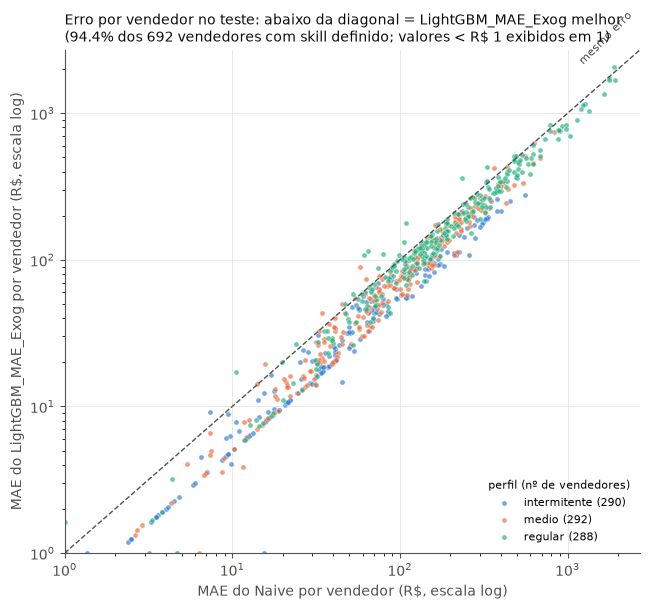

In [5]:
sel_models = list(dict.fromkeys(FOCUS + [MAIN]))
ds = D.por_vendedor(diag, MAIN, sel_models, scale_final)
A.tabela(ds, "diagnostico_principal_por_vendedor.csv")
sk = ds["skill_vs_naive"].dropna()
print(f"Vendedores com viés negativo no total do teste: {(ds[f'vies_{MAIN}'] < 0).mean():.1%}")
print(f"Vendedores em que {MAIN} erra menos que o Naive: {(sk > 0).sum()} de {len(sk)} ({(sk > 0).mean():.1%})")
print(f"Vendedores sem nenhuma venda no teste: {int((ds['real_total'] == 0).sum())}")
conc = ds.sort_values(f"erro_abs_total_{MAIN}", ascending=False)
tot = conc[f"erro_abs_total_{MAIN}"].sum()
print(f"Concentração: 10 vendedores = {conc[f'erro_abs_total_{MAIN}'].head(10).sum() / tot:.1%} do erro; "
      f"10% dos vendedores = {conc[f'erro_abs_total_{MAIN}'].head(int(np.ceil(0.1 * len(conc)))).sum() / tot:.1%}")
fig = graficos.erro_por_vendedor(ds, MAIN); A.figura(fig, "diagnostico_erro_por_vendedor.png"); plt.show()

### 23.4–23.5 Erros por perfil e por semana

Referência trivial — MAE de prever zero sempre:


perfil,intermitente,medio,regular,todos
MAE de prever zero,39.2328,85.9066,355.9719,159.7496


,perfil,modelo,n_vendedores,MAE,MAE zero,MAE positiva,Viés R$,Viés %,P90 erro,P95 erro,n_picos,% picos subestimados,skill vs Naive
0,intermitente,CatBoost_MAE,290,38.8067,0.6579,284.7573,-37.5865,-95.8039,87.2799,217.1484,66,100.0000,0.3823
1,intermitente,CatBoost_MAE_Exog,290,38.8297,0.4223,286.4471,-38.0491,-96.9828,89.0278,217.6661,66,100.0000,0.3819
2,intermitente,CatBoost_MAE_raw,290,42.2181,6.6858,271.2994,-30.3559,-77.3737,83.1118,207.5113,66,100.0000,0.3280
3,intermitente,CatBoost_Tweedie,290,61.1830,32.9813,243.0027,-3.6282,-9.2479,103.4153,190.6563,66,100.0000,0.0261
6,intermitente,LightGBM_MAE,290,39.1898,2.1049,278.2809,-35.0943,-89.4515,90.1800,212.3875,66,100.0000,0.3762
7,intermitente,LightGBM_MAE_Exog,290,38.7895,1.4477,279.5370,-35.7112,-91.0240,89.6210,213.6618,66,100.0000,0.3826
8,intermitente,MediaMovel4,290,59.4495,31.6333,238.7840,0.6805,1.7344,166.0975,294.2197,66,100.0000,0.0537
9,intermitente,Naive,290,62.8222,29.1146,280.1393,0.0486,0.1238,172.0200,346.6015,66,100.0000,0.0000
10,medio,CatBoost_MAE,292,77.0790,7.1700,252.5063,-62.3312,-72.5569,226.2697,402.3954,132,99.2424,0.2298
11,medio,CatBoost_MAE_Exog,292,77.8760,5.5198,259.4443,-67.5984,-78.6882,229.1920,408.0585,132,100.0000,0.2219


Semanas em que LightGBM_MAE_Exog erra menos que o Naive: 34 de 34
Semanas com viés negativo de LightGBM_MAE_Exog: 32 de 34


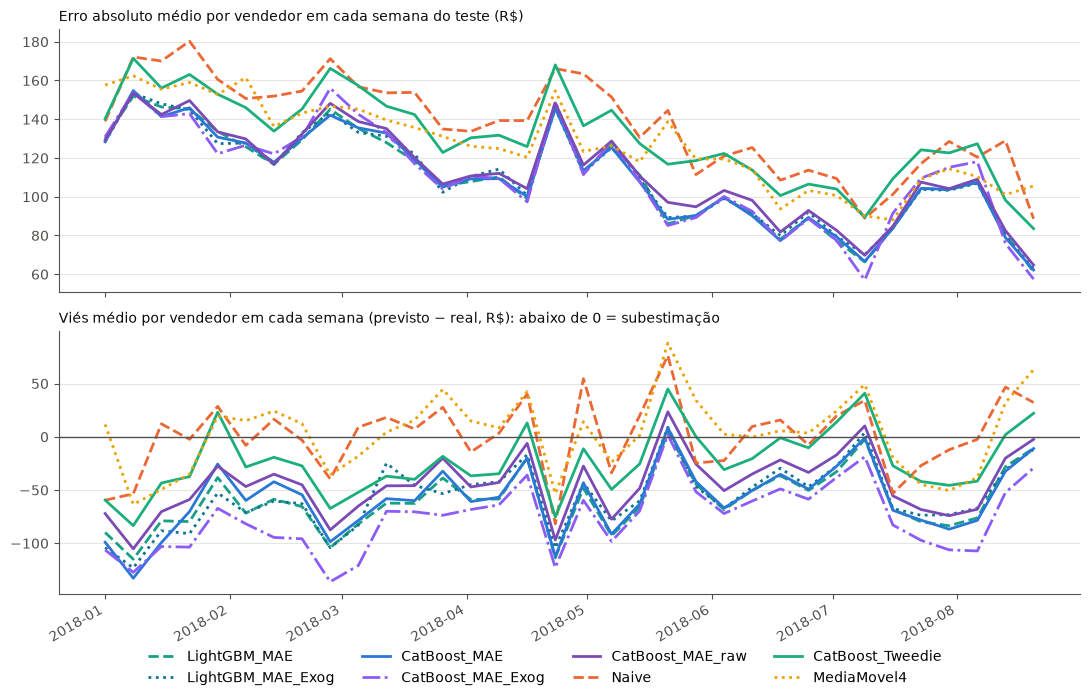

In [6]:
dp, zero_ref = D.por_perfil(diag, MODELS, thr["SIGNAL_THRESHOLD"])
A.tabela(dp, "diagnostico_por_perfil.csv")
print("Referência trivial — MAE de prever zero sempre:"); display(zero_ref.to_frame().T)
display(dp.loc[dp["modelo"].isin(FOCUS)])

dw = D.por_semana(diag, MODELS)
A.tabela(dw, "diagnostico_por_semana.csv")
print(f"Semanas em que {MAIN} erra menos que o Naive: {(dw[f'MAE_{MAIN}'] < dw['MAE_Naive']).sum()} de {len(dw)}")
print(f"Semanas com viés negativo de {MAIN}: {(dw[f'vies_{MAIN}'] < 0).sum()} de {len(dw)}")
fig = graficos.erro_por_semana(dw, FOCUS); A.figura(fig, "diagnostico_erro_por_semana.png"); plt.show()

### 23.6–23.7 Maiores erros, concentração e picos

Dos 20 maiores erros de LightGBM_MAE_Exog: 20 subestimações, 20 em picos


,n_picos,MAE nos picos,Viés nos picos,% picos subestimados,% picos superestimados,Real médio nos picos,Previsto médio nos picos,Previsto/real,Mediana previsto/real (individual),% picos com previsão acima do limiar (cobertura),n previsões acima do limiar,% previsões acima do limiar que eram pico (precisão)
modelo,,,,,,,,,,,,
Naive,1128,"1,134.3350",-506.0767,69.7695,30.2305,"2,192.4005","1,686.3238",0.7692,0.6612,57.8901,1140,57.2807
MediaMovel4,1128,"1,058.6992",-574.2864,73.6702,26.3298,"2,192.4005","1,618.1141",0.7381,0.6615,57.0922,986,65.3144
HistGB_MAE,1128,"2,130.5000","-2,111.1676",99.2021,0.7979,"2,192.4005",81.2329,0.0371,0.0000,2.6596,30,100.0000
HistGB_Poisson,1128,"1,039.2170",-618.4898,71.7199,28.2801,"2,192.4005","1,573.9107",0.7179,0.6628,57.1809,938,68.7633
LightGBM_MAE,1128,"1,157.3290",-902.9800,79.6099,20.3901,"2,192.4005","1,289.4205",0.5881,0.5167,49.8227,721,77.9473
LightGBM_MAE_Exog,1128,"1,151.7822",-807.7167,75.8865,24.1135,"2,192.4005","1,384.6838",0.6316,0.5394,50.1773,733,77.2169
CatBoost_MAE,1128,"1,160.7896",-870.9744,79.0780,20.9220,"2,192.4005","1,321.4261",0.6027,0.5160,50.7979,744,77.0161
CatBoost_MAE_Exog,1128,"1,235.2785","-1,105.5403",88.1206,11.8794,"2,192.4005","1,086.8602",0.4957,0.4330,44.1489,596,83.5570
CatBoost_MAE_raw,1128,"1,120.3661",-873.9012,80.4078,19.5922,"2,192.4005","1,318.4993",0.6014,0.5486,51.2411,755,76.5563


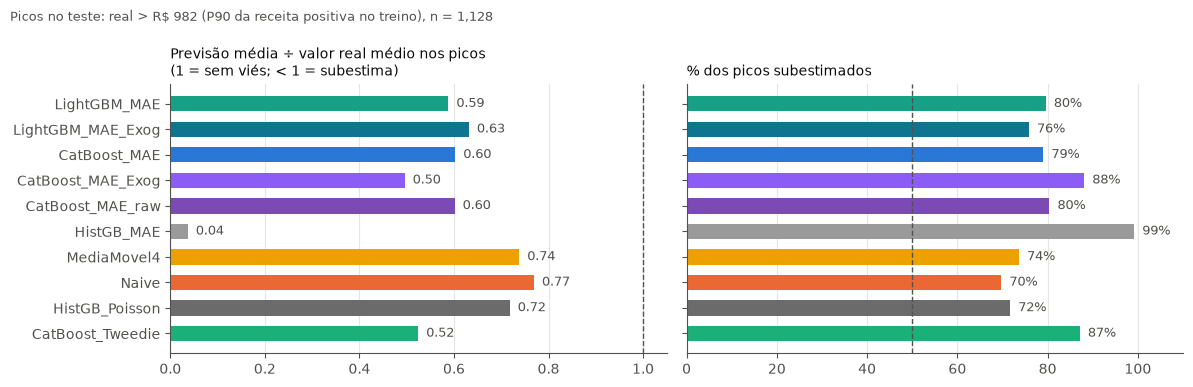

In [7]:
cols = ["seller_id", "perfil", "week_start", "target_week", "revenue_current", "rev_mean_4", "zero_weeks_prev_4",
        "y"] + [f"pred_{m}" for m in FOCUS] + [f"err_{MAIN}", "pico"]
top = diag.nlargest(20, f"abs_{MAIN}")[list(dict.fromkeys(cols))].rename(columns={"y": "real"})
A.tabela(top, "diagnostico_maiores_erros.csv")
print(f"Dos 20 maiores erros de {MAIN}: {(top[f'err_{MAIN}'] < 0).sum()} subestimações, {int(top['pico'].sum())} em picos")
A.tabela(D.concentracao(diag, MODELS), "diagnostico_concentracao_erros.csv")

picos = D.peak_table(diag, diag["pico"], "global", MODELS, thr["PEAK_THRESHOLD"], thr["seller_peak_thr"])
picos_rel = D.peak_table(diag, diag["pico_relativo"], "relativo ao vendedor", MODELS, thr["PEAK_THRESHOLD"], thr["seller_peak_thr"])
A.tabela(picos, "diagnostico_picos.csv"); A.tabela(picos_rel, "diagnostico_picos_relativos.csv")
display(picos.drop(columns="criterio").set_index("modelo"))
order_pk = [m for m in ["LightGBM_MAE", "LightGBM_MAE_Exog", "CatBoost_MAE", "CatBoost_MAE_Exog", "CatBoost_MAE_raw",
                        "HistGB_MAE", "MediaMovel4", "Naive", "HistGB_Poisson", "CatBoost_Tweedie"] if m in MODELS]
fig = graficos.picos(picos, order_pk, thr["PEAK_THRESHOLD"], int(diag["pico"].sum()))
A.figura(fig, "diagnostico_picos.png"); plt.show()

In [8]:
A.finalizar()

06_diagnostico: leu 5 artefato(s), gravou 0.
